# Chương 5 — Multilayer Perceptrons

**Người làm: Lê Sơn Trường.** Đối chiếu PDF D2L 1.0.3 trang 215–246.
Các nhận xét định lượng nằm ngay sau từng mục trong notebook, lấy từ thí nghiệm
thật. Fashion-MNIST dùng đủ 60.000 train/10.000 validation như sách.


Nguồn: [D2L chương 5](https://d2l.ai/chapter_multilayer-perceptrons/index.html). Lời giải giữ số câu để đối chiếu PDF. Chạy **Run All**; mặc định đọc cache kết quả thật. Đổi `RECOMPUTE=True` để học lại bằng nguồn `.py` đi kèm.

In [1]:
from pathlib import Path
import sys

cwd = Path.cwd().resolve()
paths = [cwd, cwd / "bai_lam_Le_Son_Truong", cwd / "Buoi2" / "bai_lam_Le_Son_Truong",
         *[p / "Buoi2" / "bai_lam_Le_Son_Truong" for p in cwd.parents]]
BASE = next((p for p in paths if (p / "experiments.py").is_file()), None)
if BASE is None:
    raise FileNotFoundError("Mở notebook trong repository DeepL hoặc thư mục bài làm Buoi2.")
sys.path.insert(0, str(BASE))
from experiments import run_section, render_result

# False: đọc lại kết quả thật đã lưu. True: chạy lại các thí nghiệm (tốn thời gian).
RECOMPUTE = False
if RECOMPUTE:
    from data import prepare
    prepare()
print("Người làm: Lê Sơn Trường | D2L 1.0.3 | CPU, seed 42")


Người làm: Lê Sơn Trường | D2L 1.0.3 | CPU, seed 42


## 5.1 — Multilayer Perceptrons (7 câu)

<details><summary>Đối chiếu đề gốc — PDF trang 215 (bấm để mở)</summary>

Bản trích text có thể mất vị trí chỉ số/số mũ; xem PDF gốc để đọc công thức chính xác.

<pre>Exercises
1. Show that adding layers to alinear deep network, i.e., a network without nonlinearity
𝜎 can never increase the expressive power of the network. Give an example where it
actively reduces it.
2. Compute the derivative of the pReLU activation function.
3. Compute the derivative of the Swish activation function𝑥 sigmoid(𝛽𝑥).
4. Show that an MLP using only ReLU (or pReLU) constructs a continuous piecewise
linear function.
5. Sigmoid and tanh are very similar.
1. Show thattanh(𝑥)+ 1 = 2 sigmoid(2𝑥).
2. Prove that the function classes parametrized by both nonlinearities are identical.
Hint: affine layers have bias terms, too.
6. Assume that we have a nonlinearity that applies to one minibatch at a time, such as the
batch normalization (Ioffe and Szegedy, 2015). What kinds of problems do you expect
this to cause?
7. Provide an example where the gradients vanish for the sigmoid activation function.
</pre>
</details>


### Câu 1

Ghép các affine không activation cho W_L…W₁x+b_eff, vẫn là affine. Ví dụ
đầu vào/ra 2D, tầng giữa chỉ 1 chiều thì hạng tích≤1, không biểu diễn được
ánh xạ identity hạng 2. Nhiều tầng tuyến tính không tăng lớp hàm, có thể giảm nó
khi có bottleneck, dù tham số hóa ảnh hưởng cách tối ưu.

### Câu 2

pReLU(x)=x nếu x≥0, αx nếu x<0. Đạo hàm theo x là 1 ở x>0, α ở x<0;
tại 0 không khả vi khi α≠1 (implementation chọn một giá trị quy ước).
Nếu α học được, ∂pReLU/∂α=x khi x<0 và 0 khi x>0.

### Câu 3

Swish=x·sigmoid(βx), đặt s=sigmoid(βx):
`d/dx=s+βx s(1−s)`. Nếu β là tham số học: `∂/∂β=x²s(1−s)`.

### Câu 4

Affine liên tục và tuyến tính từng miền; ReLU/pReLU liên tục và affine từng miền.
Ghép hữu hạn các hàm này cho hàm liên tục piecewise-affine trên các miền đa diện
(sách gọi piecewise-linear; có bias thì chính xác hơn là affine). Số miền có thể
tăng khi thêm tầng, nhưng không tạo gián đoạn tại ranh giới activation.

### Câu 5

Từ định nghĩa: tanh x=(e²ˣ−1)/(e²ˣ+1)=2sigmoid(2x)−1.
Do đó tanh(Wx+b)=2sigmoid(2Wx+2b)−1. Hệ số 2 và −1 được hấp thụ vào
trọng số/bias của tầng affine tiếp theo; chiều ngược dùng sigmoid z=(tanh(z/2)+1)/2.
Với activation ở tầng ẩn và đầu ra affine, hai lớp hàm biểu diễn tương đương
sau tái tham số hóa; điều này không bảo đảm dynamics tối ưu giống nhau.

### Câu 6

Nonlinearity phụ thuộc batch (như batch normalization khi train) làm đầu ra của
một mẫu phụ thuộc các mẫu đi cùng, kích thước batch và thống kê batch.
Batch quá nhỏ hoặc train/eval khác phân phối có thể gây nhiễu/lệch thống kê.
Phải xử lý running statistics và chế độ eval đúng; trong dữ liệu chuỗi cần tránh
thông tin tương lai lọt vào thống kê dùng cho dự đoán quá khứ.

### Câu 7

σ'(x)=σ(x)(1−σ(x))→0 khi |x| lớn, ví dụ x=±30. Nhiều tầng sigmoid nhân
các gradient nhỏ có thể làm gradient về đầu mạng rất nhỏ. Notebook đo gradient
tại −30,−10,0,10,30; FP32 ở phía bão hòa dương còn có thể làm tròn về đúng 0.

In [2]:
result = run_section("5.1", recompute=RECOMPUTE)
render_result(result)

tanh(x)+1=2 sigmoid(2x) verified numerically.


**sigmoid_gradients**

,x,gradient
0,-30.0,9.357624e-14
1,-10.0,4.539581e-05
2,0.0,2.500000e-01
3,10.0,4.541668e-05
4,30.0,0.000000e+00


## 5.2 — Implementation of MLP (9 câu)

<details><summary>Đối chiếu đề gốc — PDF trang 219 (bấm để mở)</summary>

Bản trích text có thể mất vị trí chỉ số/số mũ; xem PDF gốc để đọc công thức chính xác.

<pre>Exercises
1. Change the number of hidden unitsnum_hiddens and plot how its number affects the
accuracy of the model. What is the best value of this hyperparameter?
2. Try adding a hidden layer to see how it affects the results.
3. Whyisitabadideatoinsertahiddenlayerwithasingleneuron? Whatcouldgowrong?
4. How does changing the learning rate alter your results? With all other parameters fixed,
which learning rate gives you the best results? How does this relate to the number of
epochs?
5. Let’s optimize over all hyperparameters jointly, i.e., learning rate, number of epochs,
number of hidden layers, and number of hidden units per layer.
1. What is the best result you can get by optimizing over all of them?
2. Why it is much more challenging to deal with multiple hyperparameters?
3. Describe an efficient strategy for optimizing over multiple parameters jointly.
6. Compare the speed of the framework and the from-scratch implementation for a chal-
lenging problem. How does it change with the complexity of the network?
7. Measure the speed of tensor–matrix multiplications for well-aligned and misaligned
matrices. For instance, test for matrices with dimension 1024, 1025, 1026, 1028, and
1032.
1. How does this change between GPUs and CPUs?
2. Determine the memory bus width of your CPU and GPU.
8. Try out different activation functions. Which one works best?
9. Is there a difference between weight initializations of the network? Does it matter?
</pre>
</details>


### Câu 1

Baseline sách: 784→256→10, ReLU, SGD LR=0.1, batch=256, 10 epoch.
Notebook khảo sát 1,64,128,256,512 neuron trên cùng seed, vẽ accuracy theo độ rộng.
“Tốt nhất” chỉ là tốt nhất trong lưới này với ngân sách 10 epoch, không phải
siêu tham số tối ưu toàn cục. Kết quả cuối mục được tính tự động từ CSV.

### Câu 2

So sánh baseline một tầng 256 với hai tầng 256→256, giữ LR, batch, epoch.
Thêm tầng tăng khả năng kết hợp phi tuyến và chi phí, nhưng không bảo đảm tốt hơn;
bảng/learning curve trong notebook cho biết kết quả thực tế.

### Câu 3

Một neuron ẩn là bottleneck một chiều: nhiều đầu vào bị nén về một số.
Sau ReLU có thể chết hẳn nếu preactivation âm cho mọi mẫu. Nhiệm vụ có nhiều
lớp/đặc trưng có thể mất thông tin quan trọng, nên đây là lựa chọn quá hạn chế.
Không nói một neuron không thể giải mọi bài toán: một bài rất đơn giản vẫn có thể đủ.

### Câu 4

Giữ width=256, so LR=0.01/0.1/0.5 với 10 epoch. LR nhỏ cần nhiều epoch hơn;
LR lớn có thể hội tụ nhanh hoặc dao động. Chọn theo validation loss/accuracy và
đại lượng mục tiêu; không suy ra LR=0.5 tốt cho mọi kiến trúc chỉ từ một lần đo.

### Câu 5

Thử thêm cấu hình kết hợp: hai tầng 128 với LR=0.1, 15 epoch; hai tầng 256 với
LR=0.05, 15 epoch, rồi so với các cấu hình trước. Báo cáo cấu hình có val loss
thấp nhất và accuracy cao nhất trong tập đã đo, không tuyên bố tối ưu toàn bộ không gian.
Với k lựa chọn ở mỗi d tham số, grid đầy đủ có k^d lần fit; các yếu tố còn tương tác.
Chiến lược hiệu quả: random search trên log LR/weight decay, ngân sách ngắn cho
nhiều cấu hình rồi successive halving/ASHA, tăng ngân sách cho ứng viên tốt;
giữ test riêng nếu cần đánh giá cuối sau tuning.

### Câu 6

Notebook có bản ScratchMLP với W1,b1,W2,b2 và matmul/ReLU rõ ràng, cùng bản
nn.Sequential. Để đo công bằng, copy **cùng trọng số**, cùng batch và loss,
warm-up rồi đo forward+backward 20 lần ở width 64/256/512. Bảng timing này
tách khỏi tổng thời gian học, vì hai bản học gốc có cách khởi tạo khác nhau.
Tăng độ phức tạp có thể làm GEMM/kernel chi phối, giảm tỷ lệ overhead Python;
không khẳng định luôn framework nhanh hơn mà không xem số đo.

### Câu 7

Notebook đo matmul CPU ở 1024/1025/1026/1028/1032, lấy median sau warm-up.
Kích thước chia hết tile/SIMD có thể nhanh hơn nhưng phụ thuộc BLAS/kernel,
cache và hệ thống; không so chỉ thời gian mà quên số phép toán thay đổi theo n³.

Máy có Ryzen 9 7945HX và RTX 4060 Laptop; môi trường hiện tại cài PyTorch CPU,
`torch.cuda.is_available()` là False nên **chưa có số đo GPU**. Không giả lập
GPU timing thành kết quả thật; `benchmark_gpu.py` chạy phép đo cùng kích thước
khi dùng kernel PyTorch hỗ trợ CUDA, có synchronize trước/sau timer.

RAM báo cáo mỗi module DataWidth=64 bit; CPU hỗ trợ hai kênh theo
[AMD](https://www.amd.com/en/products/processors/laptop/ryzen/7000-series/amd-ryzen-9-7945hx.html),
nên bề rộng tổng lý thuyết 2×64=128 bit nếu hai kênh hoạt động. DDR5 có thể
chia mỗi DIMM thành các subchannel; không đồng nhất AddressWidth=64 với memory bus.
RTX 4060 Laptop có giao tiếp VRAM 128 bit theo
[NVIDIA](https://www.nvidia.com/en-ph/geforce/laptops/compare/).
Không dùng WMI AdapterRAM để suy ra dung lượng VRAM vì trường đó có giới hạn.

### Câu 8

Khảo sát ReLU/tanh/sigmoid trên mạng một tầng 256 neuron với cùng LR=0.1,
batch 256, 10 epoch. ReLU tránh bão hòa phía dương nhưng có dead neurons;
sigmoid/tanh có thể bão hòa. Lấy kết luận theo bảng cụ thể; khác LR hoặc
khởi tạo có thể thay thứ tự tốt/xấu.

### Câu 9

So zero, normal std=0.01, Xavier và default của Linear, cùng dữ liệu/seed.
Zero init ở MLP gây đối xứng; với ReLU tại 0, gradient tầng đầu có thể bằng 0,
chỉ bias đầu ra học prior lớp. Xavier/Kaiming giúp kiểm soát phương sai nhưng
cần khớp activation. Trong linear/softmax không tầng ẩn, zero init không gây
cùng dạng đối xứng neuron ẩn; xem mục 5.4.

CUDA available=False. No GPU timing or physical memory-bus width is invented. CPU word size 64bit is not memory bus width; see hardware.json.
From-scratch vs framework speeds above include initialization differences. A separate equal-weight forward/backward benchmark follows.


**comparison**

,name,epoch,train_loss,val_loss,train_accuracy,val_accuracy,h1_eval_var,seconds,hidden,lr,batch,activation,dropout,weight_decay,initialization,scratch,h2_eval_var
0,width_1,10,2.302604,2.302604,0.100000,0.1000,0.000000,1.230450,"(1,)",0.10,256,relu,"(0.0, 0.0)",0.0,default,False,NaN
1,width_64,10,0.381817,0.423548,0.865217,0.8488,0.952838,2.694069,"(64,)",0.10,256,relu,"(0.0, 0.0)",0.0,default,False,NaN
2,width_128,10,0.368949,0.412845,0.869767,0.8516,0.478260,4.173132,"(128,)",0.10,256,relu,"(0.0, 0.0)",0.0,default,False,NaN
3,width_256,10,0.367504,0.411041,0.869967,0.8520,0.253757,6.809086,"(256,)",0.10,256,relu,"(0.0, 0.0)",0.0,default,False,NaN
4,width_512,10,0.362927,0.406771,0.870767,0.8551,0.135141,11.969194,"(512,)",0.10,256,relu,"(0.0, 0.0)",0.0,default,False,NaN
5,two_layers,10,0.345295,0.394196,0.875433,0.8588,0.150506,9.313069,"(256, 256)",0.10,256,relu,"(0.0, 0.0)",0.0,default,False,0.253028
6,lr_0.01,10,0.563067,0.584918,0.812133,0.7998,0.481301,6.847379,"(256,)",0.01,256,relu,"(0.0, 0.0)",0.0,default,False,NaN
7,lr_0.5,10,0.301360,0.370444,0.888367,0.8687,0.221058,6.751992,"(256,)",0.50,256,relu,"(0.0, 0.0)",0.0,default,False,NaN
8,tanh,10,0.381716,0.422478,0.863783,0.8454,0.283031,7.398474,"(256,)",0.10,256,tanh,"(0.0, 0.0)",0.0,default,False,NaN
9,sigmoid,10,0.473978,0.501411,0.832317,0.8192,0.055279,6.984987,"(256,)",0.10,256,sigmoid,"(0.0, 0.0)",0.0,default,False,NaN


**history**

,name,epoch,train_loss,val_loss,train_accuracy,val_accuracy,h1_eval_var,h2_eval_var
0,width_1,1,2.304146,2.304157,0.100000,0.1000,0.000033,NaN
1,width_1,2,2.302649,2.302649,0.100000,0.1000,0.000000,NaN
2,width_1,3,2.302614,2.302614,0.100000,0.1000,0.000000,NaN
3,width_1,4,2.302630,2.302630,0.100000,0.1000,0.000000,NaN
4,width_1,5,2.302626,2.302626,0.100000,0.1000,0.000000,NaN
5,width_1,6,2.302615,2.302615,0.100000,0.1000,0.000000,NaN
6,width_1,7,2.302614,2.302614,0.100000,0.1000,0.000000,NaN
7,width_1,8,2.302644,2.302644,0.100000,0.1000,0.000000,NaN
8,width_1,9,2.302616,2.302616,0.100000,0.1000,0.000000,NaN
9,width_1,10,2.302604,2.302604,0.100000,0.1000,0.000000,NaN


**matrix_alignment_cpu**

,size,cpu_seconds
0,1024,0.015367
1,1025,0.015956
2,1026,0.016122
3,1028,0.015626
4,1032,0.015215


**equal_weights_speed**

,width,implementation,forward_backward_seconds
0,64,framework,0.000644
1,64,scratch,0.000638
2,256,framework,0.001794
3,256,scratch,0.001851
4,512,framework,0.003310
5,512,scratch,0.003542


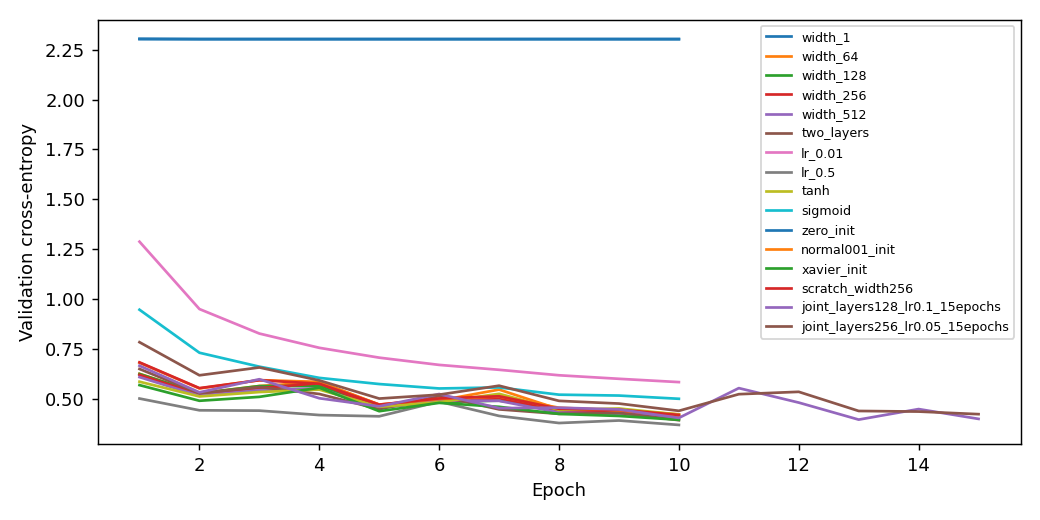

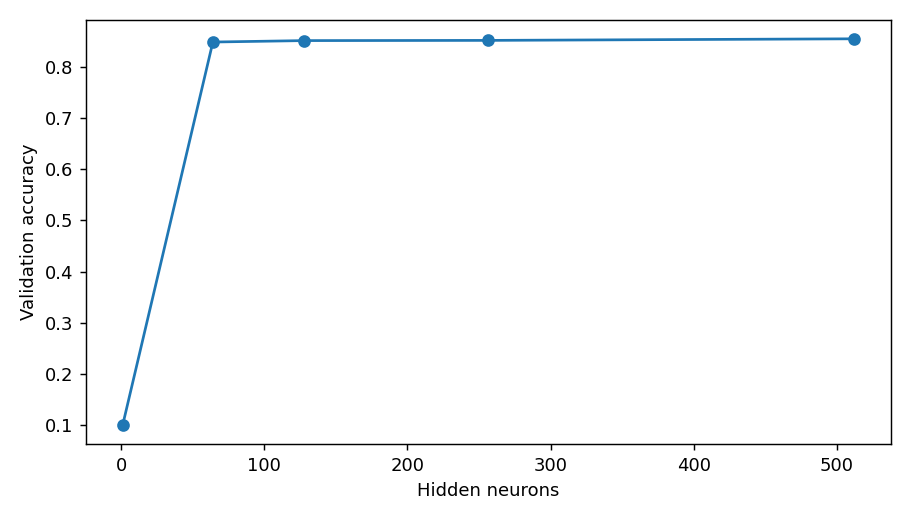

In [3]:
result = run_section("5.2", recompute=RECOMPUTE)
render_result(result)

**Nhận xét từ số đo:** trong nhóm độ rộng, width_512 có accuracy cao nhất (85.51%). Trong toàn bộ cấu hình thử, lr_0.5 có loss thấp nhất (0.3704), accuracy 86.87%. Zero init và bottleneck 1 neuron chỉ đạt 10% trong lần chạy này. Không suy rộng thành siêu tham số tối ưu toàn cục.

## 5.3 — Forward/Backward/Computational Graphs (5 câu)

<details><summary>Đối chiếu đề gốc — PDF trang 223 (bấm để mở)</summary>

Bản trích text có thể mất vị trí chỉ số/số mũ; xem PDF gốc để đọc công thức chính xác.

<pre>Exercises
1. Assume that the inputsX to some scalar function𝑓 are𝑛×𝑚 matrices. What is the
dimensionality of the gradient of𝑓 with respect toX?
2. Add a bias to the hidden layer of the model described in this section (you do not need
to include bias in the regularization term).
1. Draw the corresponding computational graph.
2. Derive the forward and backward propagation equations.
3. Computethememoryfootprintfortrainingandpredictioninthemodeldescribedinthis
section.
4. Assume that you want to compute second derivatives. What happens to the computa-
tional graph? How long do you expect the calculation to take?
184 Multilayer Perceptrons
104
5. Assume that the computational graph is too large for your GPU.
1. Can you partition it over more than one GPU?
2. What are the advantages and disadvantages over training on a smaller minibatch?
</pre>
</details>


### Câu 1

Loss scalar f và X shape n×m ⇒ gradient ∂f/∂X cũng shape n×m,
mỗi phần tử là độ nhạy của f theo phần tử tương ứng của X.

### Câu 2

Theo quy ước batch hàng: Z=XW1+1b1ᵀ; H=φ(Z); O=HW2;
J=L(O,Y)+(λ/2)(‖W1‖²_F+‖W2‖²_F), không phạt b1.
Đồ thị ở notebook: X,W1,b1→Z→H; H,W2→O; O,Y→L; W1,W2→R; L,R→J.

Đặt G=∂L/∂O; với softmax-CE mean, G=(softmax(O)−onehot(Y))/N.
Backward:

- ∂J/∂W2=HᵀG+λW2.
- D=(GW2ᵀ)⊙φ'(Z).
- ∂J/∂W1=XᵀD+λW1; ∂J/∂b1=Σ_hàng D; ∂J/∂X=DW1ᵀ.

Với vector cột, transpose các ma trận theo quy ước của sách; không trộn hai quy ước.

### Câu 3

Input d, hidden h, output q, batch N: mô hình gốc không bias có P₀=dh+hq;
phiên bản thêm hidden bias ở câu 2 có P=P₀+h tham số.
FP32 tham số chiếm 4P byte, gradient thêm 4P; SGD thuần không có momentum state,
Adam thêm khoảng 8P cho hai moment. Các activation X,Z,H,O có khoảng
N(d+2h+q) phần tử lưu cho backward, thêm bộ nhớ loss/workspace/mask tùy framework.
Ví dụ FP32, d=784,h=256,q=10,N=32: mô hình gốc có 203.264 tham số
(813.056 byte), mô hình thêm bias có 203.520 tham số (814.080 byte).
Prediction không giữ graph/gradient, cần tham số và activation đang dùng; peak
phụ thuộc tái sử dụng buffer, không thể cho một số byte duy nhất nếu chưa chỉ rõ
batch,dtype,optimizer và implementation.

### Câu 4

Phải giữ graph của gradient (`create_graph=True`); graph mới gồm cả phép tính
backward. Hessian đầy đủ có P² phần tử và thường cần nhiều lượt, tốn hơn bậc một.
HVP chỉ cần directional derivative của gradient, tránh materialize Hessian.
Notebook kiểm tra f=Σx³ có H·1=6x.

### Câu 5

Có thể partition theo tầng/pipeline/model parallel qua nhiều GPU, truyền
activation và gradient giữa thiết bị. Ưu điểm: mô hình lớn hơn VRAM một GPU;
nhược: communication, pipeline bubble, đồng bộ và triển khai phức tạp.
Giảm minibatch đơn giản hơn và giảm activation memory, nhưng không giảm kích
thước tham số/optimizer state; model parallel/sharding cần khi phần này đã quá lớn.

X shape=(5, 3), gradient shape=(5, 3), b1 gradient shape=(4,)
Graph: X,W1,b1 -> Z -> ReLU -> H; H,W2 -> O; O,Y -> loss; weight matrices -> L2 -> objective.
Second-derivative Hessian-vector product=[6.0, 12.0]


**memory_accounting**

,model,parameters,parameter_bytes_fp32,parameter_plus_gradient_bytes_fp32,stored_X_Z_H_O_bytes_fp32
0,original_no_bias,203264,813056,1626112,167168
1,hidden_bias_added,203520,814080,1628160,167168


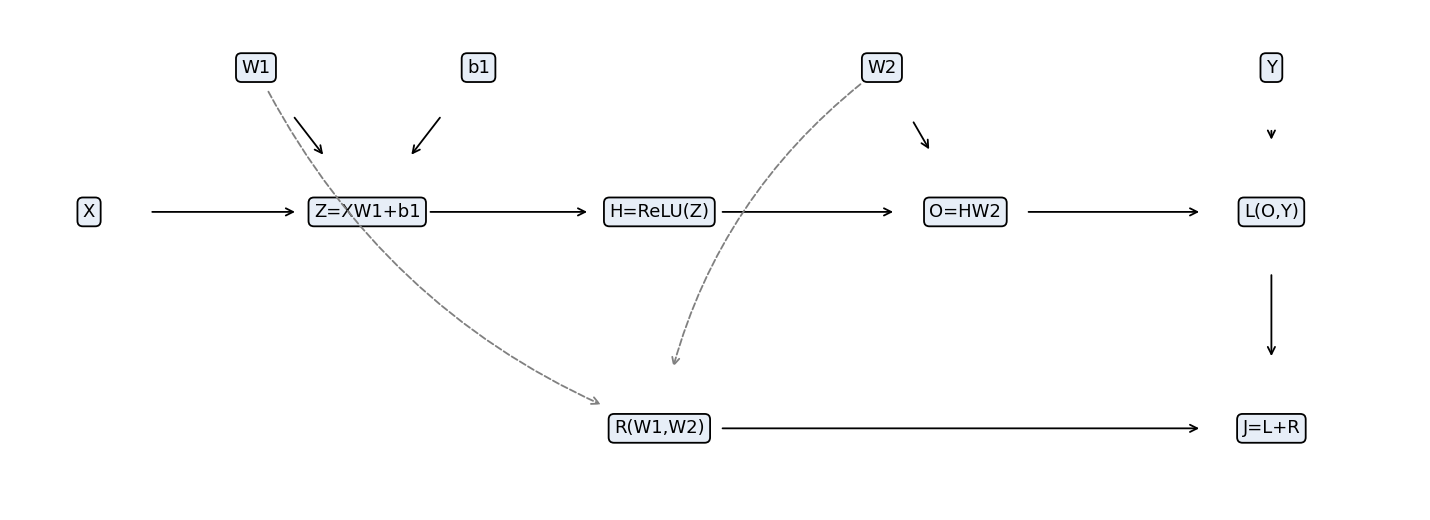

In [4]:
result = run_section("5.3", recompute=RECOMPUTE)
render_result(result)

## 5.4 — Numerical Stability and Initialization (4 câu)

<details><summary>Đối chiếu đề gốc — PDF trang 228 (bấm để mở)</summary>

Bản trích text có thể mất vị trí chỉ số/số mũ; xem PDF gốc để đọc công thức chính xác.

<pre>Exercises
1. Can you design other cases where a neural network might exhibit symmetry that needs
breaking, besides the permutation symmetry in an MLP’s layers?
2. Can we initialize all weight parameters in linear regression or in softmax regression to
the same value?
3. Look up analytic bounds on the eigenvalues of the product of two matrices. What does
this tell you about ensuring that gradients are well conditioned?
4. If we know that some terms diverge, can we fix this after the fact? Look at the paper on
layerwise adaptive rate scaling for inspiration (Youet al., 2017).
</pre>
</details>


### Câu 1

Các filter convolution giống nhau trong cùng nhóm hoặc attention heads có toàn bộ
tham số/đường đi giống nhau có thể nhận gradient giống nhau, học trùng chức năng.
Các nhánh residual song song khởi tạo giống nhau cũng có đối xứng tương tự.
Phá bằng khởi tạo ngẫu nhiên độc lập hoặc thiết kế bất đối xứng có chủ đích.

### Câu 2

Linear regression có thể khởi tạo cùng giá trị, kể cả 0. Softmax cũng có thể zero:
nhãn từng lớp tạo gradient khác nhau `Xᵀ(p−y)` nên các cột không nhất thiết giữ
giống nhau. Vấn đề đối xứng nặng là nhiều neuron ẩn đồng vai trò cùng tham số,
không phải mọi mô hình có nhiều tham số đều cấm zero init.

### Câu 3

Không có quy tắc nhân riêng eigenvalue cho hai ma trận bất kỳ. Ví dụ hai ma trận
tam giác A=[[1,M],[0,1]], B=Aᵀ đều có eigenvalue 1, nhưng AB có eigenvalue
lớn cỡ M². Notebook kiểm tra M=100.

Với spectral norm/singular value: σmax(AB)≤σmax(A)σmax(B);
với ma trận vuông khả nghịch σmin(AB)≥σmin(A)σmin(B), nên κ₂(AB)≤κ₂(A)κ₂(B).
Gradient qua nhiều tầng chứa tích Jacobian: σ lớn gây explode, nhỏ gây vanish.
Khởi tạo tốt cần kiểm soát singular values/phương sai và activation, không chỉ eigenvalue.

### Câu 4

LARS dùng local rate gần `η_l=η·τ‖w_l‖/(‖g_l‖+β‖w_l‖+ε)` để scale bước
cập nhật tương đối theo norm tầng; xem
[You, Gitman, Ginsburg 2017](https://arxiv.org/abs/1708.03888).
Có thể dùng giảm LR/warm-up, clipping, normalization và khởi tạo phù hợp để phòng
divergence. Nếu tham số đã thành Inf/NaN, scale sau đó không khôi phục thông tin;
cần phát hiện trước update hoặc quay lại checkpoint hợp lệ. LARS không bảo đảm
sửa mọi dạng bất ổn và không phải một phép “chữa” NaN sau khi mất dữ liệu.

In [5]:
result = run_section("5.4", recompute=RECOMPUTE)
render_result(result)

Eigenvalues A=[1.0, 1.0], B=[1.0, 1.0], AB=[10001.999900019995, 9.998000499855664e-05]
Individual eigenvalues do not control a non-normal product; singular-value bounds are the safe general gradient bounds.


## 5.5 — Generalization in Deep Learning (5 câu)

<details><summary>Đối chiếu đề gốc — PDF trang 233 (bấm để mở)</summary>

Bản trích text có thể mất vị trí chỉ số/số mũ; xem PDF gốc để đọc công thức chính xác.

<pre>Exercises
1. Inwhatsensedotraditionalcomplexity-basedmeasuresfailtoaccountforgeneralization
of deep neural networks?
2. Why mightearly stoppingbe considered a regularization technique?
3. How do researchers typically determine the stopping criterion?
4. What important factor seems to differentiate cases when early stopping leads to big
improvements in generalization?
5. Beyond generalization, describe another benefit of early stopping.
</pre>
</details>


### Câu 1

Mạng quá tham số có thể fit nhãn ngẫu nhiên nhưng vẫn tổng quát hóa trên dữ liệu
có cấu trúc. Capacity worst-case theo số tham số/VC thường cho cận quá lỏng,
bỏ qua dữ liệu, margin/norm, nghiệm và implicit bias của thuật toán tối ưu.
Không có nghĩa complexity vô nghĩa, chỉ các thước đo thô chưa giải thích đầy đủ.

### Câu 2

Early stopping hạn chế thời gian tối ưu/độ phức tạp hữu hiệu của nghiệm, ngăn
mô hình tiếp tục fit nhiễu train. Với một số bài toán tuyến tính nó có liên hệ
spectral regularization, nhưng không đồng nhất mọi early stopping với cùng một L2.

### Câu 3

Theo dõi validation metric định trước, lưu best checkpoint và dừng sau patience
khi không cải thiện đủ min_delta. Chọn metric/độ kiên nhẫn trước khi nhìn test.
Notebook chọn epoch min validation loss từ một đường học đã đo, không giả định
epoch đó luôn có accuracy cao nhất.

### Câu 4

Lợi ích lớn hơn khi có khoảng cách train/validation, nhãn nhiễu hoặc mô hình
có khả năng ghi nhớ và validation bắt đầu xấu đi trong lúc train còn tốt lên.
Nếu cả hai đang cải thiện hoặc đã plateau giống nhau, early stopping có thể
không cải thiện accuracy; phải xem dữ liệu và đường học cụ thể.

### Câu 5

Tiết kiệm thời gian, điện và chi phí tính toán; dùng ngân sách cho nhiều cấu hình
hơn. Lợi ích tài nguyên vẫn tồn tại ngay khi generalization không tăng.

In [6]:
result = run_section("5.5", recompute=RECOMPUTE)
render_result(result)

Checkpoint is selected from a measured curve, not assumed to outperform final training. The curve is softmax from section 4.5, used only to demonstrate the criterion.


**early_stopping**

,selected_epoch,selected_val_loss,selected_val_accuracy,final_epoch,final_val_loss,final_val_accuracy
0,18,0.461317,0.8367,20,0.466817,0.8314


## 5.6 — Dropout (7 câu)

<details><summary>Đối chiếu đề gốc — PDF trang 238 (bấm để mở)</summary>

Bản trích text có thể mất vị trí chỉ số/số mũ; xem PDF gốc để đọc công thức chính xác.

<pre>Exercises
1. What happens if you change the dropout probabilities for the first and second layers?
In particular, what happens if you switch the ones for both layers? Design an experi-
ment to answer these questions, describe your results quantitatively, and summarize the
qualitative takeaways.
2. Increase the number of epochs and compare the results obtained when using dropout
with those when not using it.
3. What is the variance of the activations in each hidden layer when dropout is and is not
applied? Draw a plot to show how this quantity evolves over time for both models.
4. Why is dropout not typically used at test time?
5. Using the model in this section as an example, compare the effects of using dropout and
199 Predicting House Prices on Kaggle
107
108
weightdecay. Whathappenswhendropoutandweightdecayareusedatthesametime?
Are the results additive? Are there diminished returns (or worse)? Do they cancel each
other out?
6. What happens if we apply dropout to the individual weights of the weight matrix rather
than the activations?
7. Invent another technique for injecting random noise at each layer that is different from
the standard dropout technique. Can you develop a method that outperforms dropout on
the Fashion-MNIST dataset (for a fixed architecture)?
</pre>
</details>


### Câu 1

Giữ kiến trúc hai tầng 256→256, LR=0.1, batch256; so p=(0.2,0.5),
(0.5,0.2), baseline không dropout và cấu hình sách (0.5,0.5).
Bảng ghi accuracy/loss thật; các cặp hoán đổi chạy cùng 20 epoch.
Drop sớm hơn có thể làm mất tín hiệu đầu vào tầng sau nhiều hơn; không suy ra
hoán đổi p luôn cho kết quả như nhau dù tổng p bằng nhau.

### Câu 2

Hai cấu hình có dropout và baseline không dropout chạy 20 epoch, xuất kết quả
ở epoch10 và epoch20 trên cùng run. Tăng epoch có thể giúp mạng dropout học
bù nhiễu; cũng có thể baseline overfit. Kết luận theo số đo, không hứa dropout luôn thắng.

### Câu 3

Inverted dropout z=m·h/(1−p), m~Bernoulli(1−p). Với h cố định,
E[z|h]=h và Var(z|h)=p·h²/(1−p); không dropout thì mask variance=0.
Nếu H ngẫu nhiên độc lập mask:
Var(Z)=Var(H)+p·E[H²]/(1−p).
Notebook đo empirical variance qua 1.024 ảnh cố định và toàn bộ units ở mỗi
tầng, theo epoch. **Eval và train được chạy riêng**: đường eval tắt toàn bộ dropout;
đường train bật dropout đúng như lúc học. Lưu/khôi phục RNG và mode quanh phép
đo để không làm thay đổi mask của epoch tiếp theo. Đó không phải cùng đại lượng
với variance theo mask khi giữ một activation h cố định; đồ thị ghi rõ cách đo.

### Câu 4

Inference tiêu chuẩn tắt dropout vì inverted dropout đã giữ kỳ vọng khi train;
để mask ngẫu nhiên làm dự đoán biến động không cần thiết. Ngoại lệ MC dropout
cố ý giữ mask và lấy nhiều lần dự đoán để khảo sát bất định; phải thiết kế/đánh giá riêng.

### Câu 5

So baseline, dropout, weight decay=1e−4 và cả hai trên cùng kiến trúc/20 epoch.
Hai cơ chế khác nhau: dropout tạo nhiễu activation, weight decay hạn chế trọng số.
Hiệu quả không nhất thiết cộng; kết hợp có thể lợi ích giảm dần hoặc regularize
quá mạnh. Bảng định lượng trong notebook là căn cứ kết luận cho dữ liệu này.

### Câu 6

Drop trực tiếp trọng số tạo `Wtilde=M⊙W/(1−p)` (DropConnect).
Các output units có mẫu nhiễu liên kết khác activation dropout; phải tính mask
trên ma trận, tắt khi eval, kỳ vọng affine vẫn giữ nhưng kỳ vọng sau nonlinearity
không nhất thiết bằng output mạng mean. Không coi hai kỹ thuật tương đương.

### Câu 7

Thử thêm Gaussian noise mean0,std=0.15 vào mỗi tầng ẩn khi train, tắt lúc eval;
giữ cùng kiến trúc/20 epoch với dropout. Notebook so sánh thật trên Fashion-MNIST.
Nếu không thắng dropout thì báo đúng; câu hỏi mang tính nghiên cứu, không có
bảo đảm một kỹ thuật mới tự nghĩ luôn vượt baseline. Có thể tuning std bằng
validation, nhưng cần ngân sách và test độc lập để khẳng định cải thiện bền vững.

Noise/dropout can help or hurt; compare measured validation scores, no promise Gaussian noise wins. Eval and stochastic train variance are measured in separate forwards on 1024 fixed images. RNG and module modes are restored, so monitoring does not alter later training masks. Empirical variance across samples and units differs from conditional mask variance p/(1-p)*h^2.


**comparison**

,name,epoch,train_loss,val_loss,train_accuracy,val_accuracy,h1_eval_var,h2_eval_var,h1_before_dropout_var,h1_after_dropout_var,...,hidden,lr,batch,activation,dropout,weight_decay,initialization,scratch,h1_after_noise_var,h2_after_noise_var
0,no_dropout,20,0.277244,0.348396,0.897100,0.8730,0.137468,0.240724,0.137468,0.137468,...,"(256, 256)",0.1,256,relu,"(0.0, 0.0)",0.0000,default,False,NaN,NaN
1,dropout_02_05,20,0.290213,0.354176,0.892950,0.8712,0.080846,0.165075,0.080846,0.106242,...,"(256, 256)",0.1,256,relu,"(0.2, 0.5)",0.0000,default,False,NaN,NaN
2,dropout_05_02,20,0.298256,0.359903,0.889733,0.8701,0.076161,0.177574,0.076161,0.171786,...,"(256, 256)",0.1,256,relu,"(0.5, 0.2)",0.0000,default,False,NaN,NaN
3,book_dropout_05_05,10,0.358442,0.401914,0.867283,0.8546,0.079898,0.190540,0.079898,0.182337,...,"(256, 256)",0.1,256,relu,"(0.5, 0.5)",0.0000,default,False,NaN,NaN
4,weight_decay,20,0.282259,0.351110,0.895533,0.8727,0.136245,0.238311,0.136245,0.136245,...,"(256, 256)",0.1,256,relu,"(0.0, 0.0)",0.0001,default,False,NaN,NaN
5,dropout_plus_decay,20,0.292897,0.355896,0.892367,0.8706,0.080356,0.160924,0.080356,0.105617,...,"(256, 256)",0.1,256,relu,"(0.2, 0.5)",0.0001,default,False,NaN,NaN
6,gaussian_noise,20,0.300873,0.362939,0.887017,0.8677,0.210370,0.320548,0.210370,0.210370,...,"(256, 256)",0.1,256,relu,"(0.0, 0.0)",0.0000,default,False,0.232553,0.346541


**history**

,name,epoch,train_loss,val_loss,train_accuracy,val_accuracy,h1_eval_var,h2_eval_var,h1_before_dropout_var,h1_after_dropout_var,h2_before_dropout_var,h2_after_dropout_var,h1_after_noise_var,h2_after_noise_var
0,no_dropout,1,0.628965,0.650702,0.788283,0.7755,0.278130,0.339715,0.278130,0.278130,0.339715,0.339715,NaN,NaN
1,no_dropout,2,0.503154,0.529093,0.826783,0.8165,0.232880,0.310429,0.232880,0.232880,0.310429,0.310429,NaN,NaN
2,no_dropout,3,0.523306,0.560233,0.800400,0.7835,0.213551,0.309699,0.213551,0.213551,0.309699,0.309699,NaN,NaN
3,no_dropout,4,0.492692,0.525465,0.827817,0.8165,0.194247,0.288269,0.194247,0.194247,0.288269,0.288269,NaN,NaN
4,no_dropout,5,0.412031,0.449034,0.852983,0.8399,0.174975,0.261808,0.174975,0.174975,0.261808,0.261808,NaN,NaN
5,no_dropout,6,0.469469,0.514898,0.823250,0.8041,0.171089,0.260995,0.171089,0.171089,0.260995,0.260995,NaN,NaN
6,no_dropout,7,0.407153,0.448291,0.852367,0.8364,0.166682,0.261958,0.166682,0.166682,0.261958,0.261958,NaN,NaN
7,no_dropout,8,0.385675,0.426135,0.858217,0.8443,0.148342,0.242143,0.148342,0.148342,0.242143,0.242143,NaN,NaN
8,no_dropout,9,0.380224,0.430893,0.861833,0.8428,0.155185,0.257268,0.155185,0.155185,0.257268,0.257268,NaN,NaN
9,no_dropout,10,0.345295,0.394196,0.875433,0.8588,0.150506,0.253028,0.150506,0.150506,0.253028,0.253028,NaN,NaN


**longer_training**

,name,epoch10_accuracy,epoch20_accuracy
0,no_dropout,0.8588,0.8730
1,dropout_02_05,0.8555,0.8712
2,dropout_05_02,0.8548,0.8701


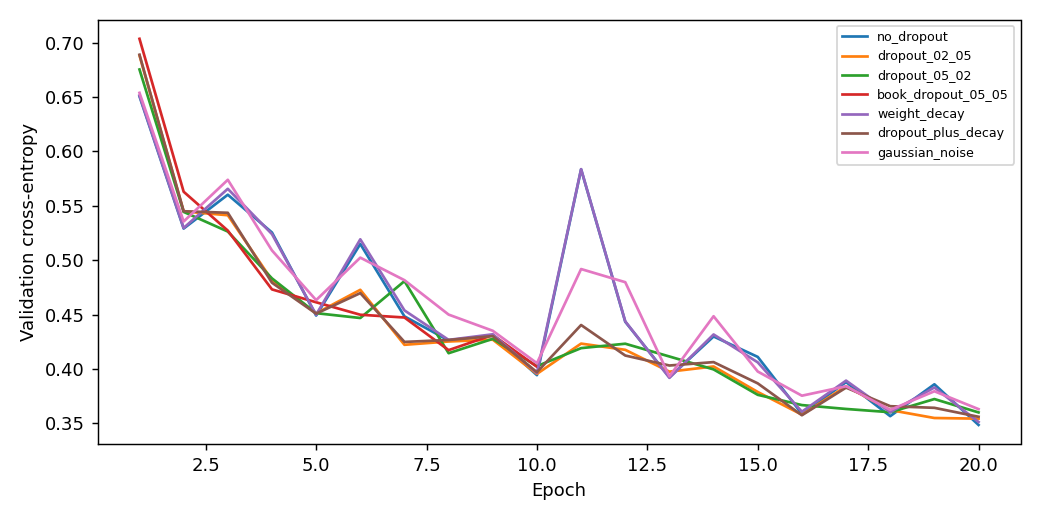

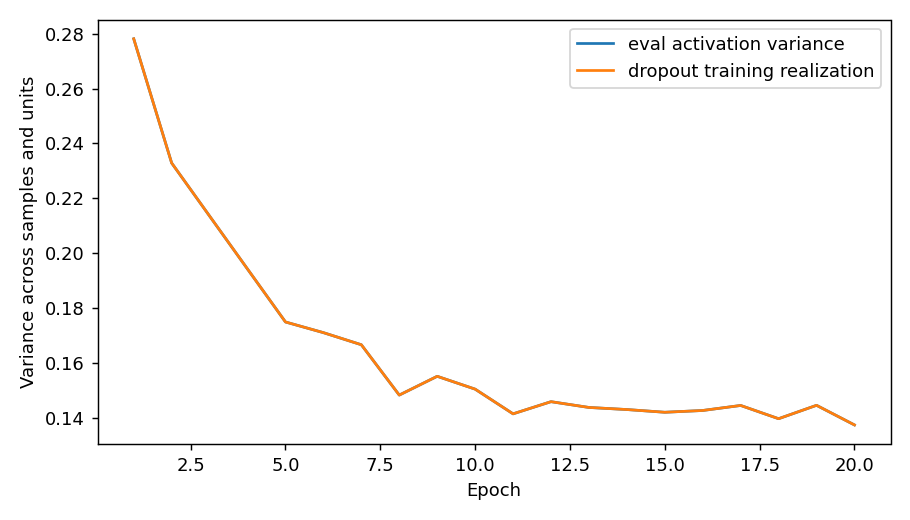

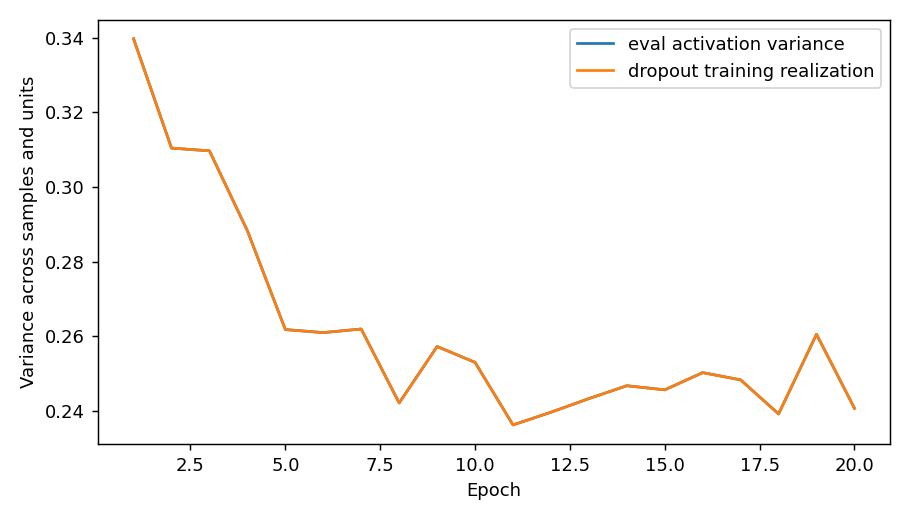

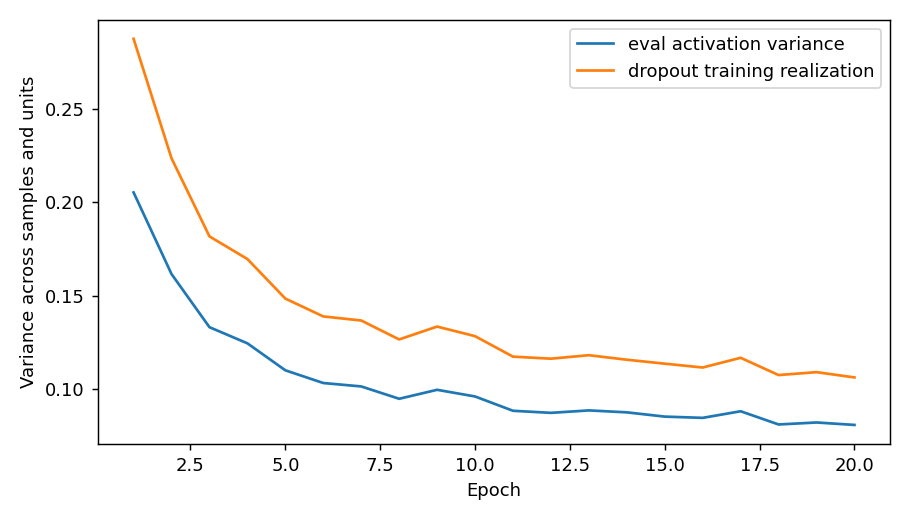

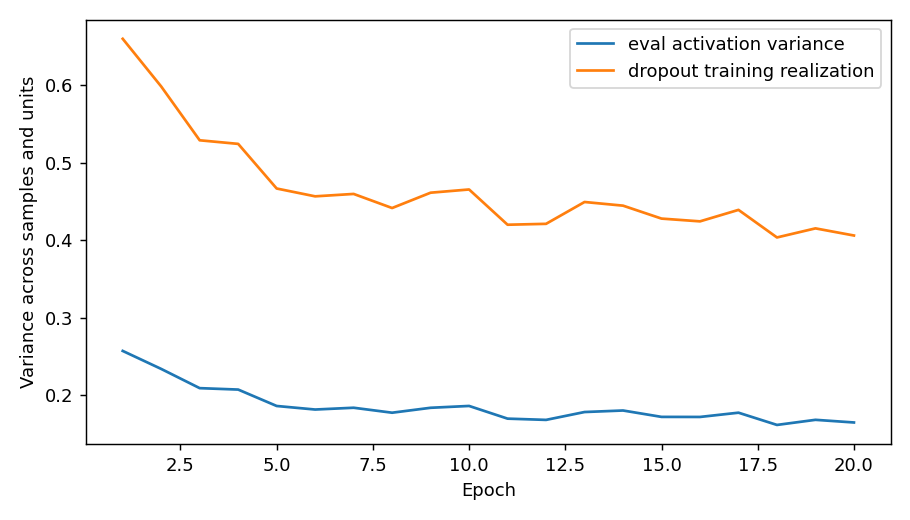

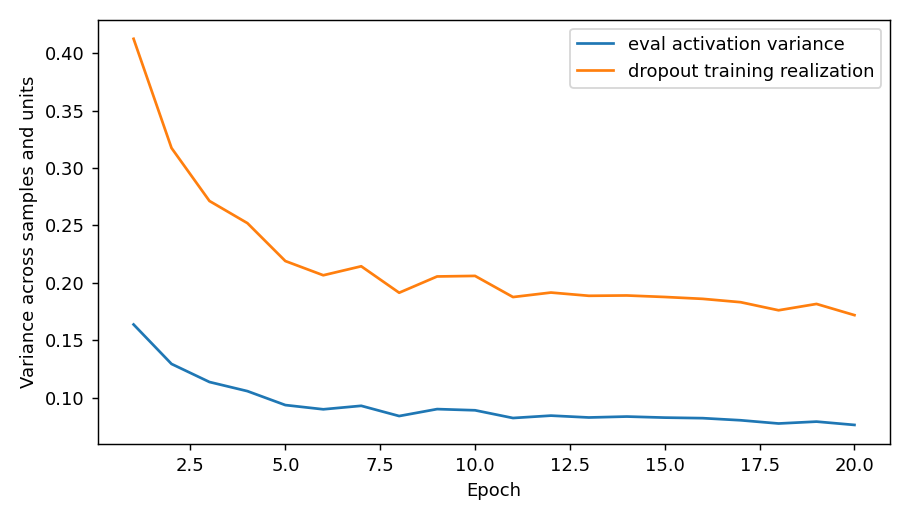

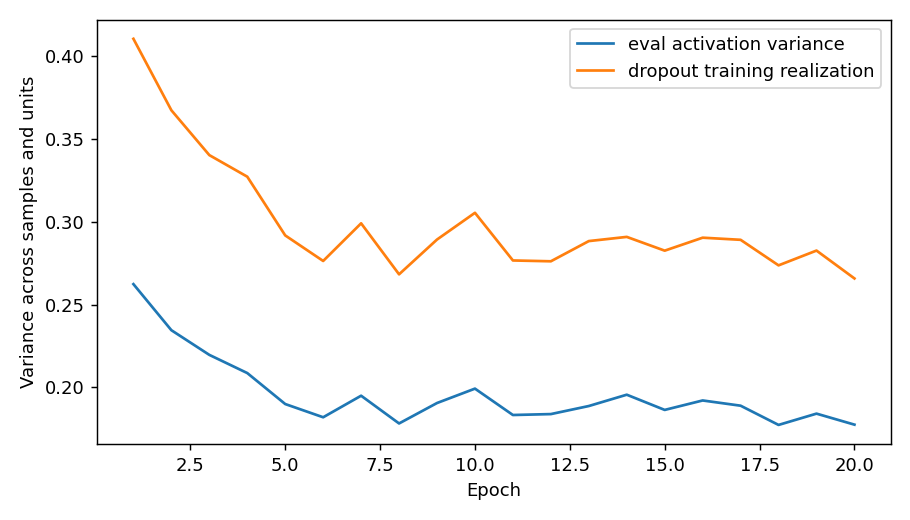

In [7]:
result = run_section("5.6", recompute=RECOMPUTE)
render_result(result)

**Nhận xét từ số đo tại 20 epoch:** không dropout 87.30%; p=(0.2,0.5) 87.12%; p=(0.5,0.2) 87.01%; weight decay 87.27%; kết hợp 87.06%; Gaussian noise 86.77%. Các mức regularization này chưa vượt baseline không dropout; không bịa kết luận cải thiện.

## 5.7 — Predicting House Prices on Kaggle (5 câu)

<details><summary>Đối chiếu đề gốc — PDF trang 246 (bấm để mở)</summary>

Bản trích text có thể mất vị trí chỉ số/số mũ; xem PDF gốc để đọc công thức chính xác.

<pre>Exercises
1. Submit your predictions for this section to Kaggle. How good are they?
2. Is it always a good idea to replace missing values by a mean? Hint: can you construct a
situation where the values are not missing at random?
3. Improve the score by tuning the hyperparameters through𝐾-fold cross-validation.
4. Improve the score by improving the model (e.g., layers, weight decay, and dropout).
5. What happens if we do not standardize the continuous numerical features as we have
done in this section?
</pre>
</details>


### Câu 1

Đã xây pipeline tạo **Le_Son_Truong_submission.csv**, hai cột Id/SalePrice,
1.459 dòng, dự đoán giá dương bằng trung bình dự đoán giá của 5 mô hình fold.
Đã kiểm tra schema, ID, số dòng và số hữu hạn. **Chưa nộp lên Kaggle và chưa có
điểm leaderboard**; điểm 5-fold local không được ghi thành điểm Kaggle.
Bạn đăng nhập, chấp nhận quy tắc House Prices và upload CSV ở trang cuộc thi:
https://www.kaggle.com/competitions/house-prices-advanced-regression-techniques.
Sau khi có điểm, chụp màn hình và bổ sung vào hồ sơ. Đây là bước còn cần tài khoản cá nhân.

### Câu 2

Không luôn nên mean-impute. Ví dụ giá trị thu nhập cao dễ bị người trả lời bỏ trống:
missingness phụ thuộc chính giá trị không quan sát (MNAR), mean từ người trả lời
bị thiên lệch. Với nhà không có garage, missing diện tích garage có thể nghĩa là
không tồn tại, không phải gara “trung bình”. Cần hiểu ngữ nghĩa, có missing indicator,
imputation có điều kiện hoặc mô hình phù hợp; mọi thống kê chỉ fit trên train fold.

### Câu 3

Notebook dùng 5-fold cố định seed42 để so baseline linear SGD LR=.01,10 epoch
của sách với 100 epoch và weight decay. Báo cáo mean±std **log RMSE**;
sách có chỗ in log MSE, phải phân biệt MSE với căn của nó khi so sánh.
Chọn cấu hình theo CV, không dùng test labels. Lưới hữu hạn không bảo đảm tối ưu
toàn cục; repeated tuning có selection bias.

### Câu 4

Thử MLP một tầng64 và hai tầng64→32, ReLU, Adam LR=.003,100 epoch,
Dropout .1 và decay tương ứng 1e−4/1e−3. Đây là mở rộng được câu hỏi yêu cầu,
không phải giả định sách mặc định dùng Adam/100 epoch.
So CV với baseline, chọn mô hình tốt nhất trong tập đo rồi ensemble 5 fold để
dự đoán. Mạng sâu hơn không nhất thiết tốt hơn dữ liệu bảng nhỏ.

### Câu 5

Bỏ scaling làm các feature chênh lệch độ lớn khiến tối ưu kém điều kiện,
gradient bị biến có scale lớn chi phối; cùng LR có thể phân kỳ. Notebook chạy
baseline không scale ở fold1 và ghi trạng thái finite/diverged thực tế.
Scaling còn ảnh hưởng ý nghĩa regularization. Bản này fit mean/std và category
trong mỗi train fold rồi áp cho validation/test, thay vì dùng toàn bộ train+test
như cách đơn giản minh họa trong sách, để tránh leakage thống kê trong CV.

Selected config=mlp64_dropout; 5-fold log RMSE=0.26146; submission=Le_Son_Truong_submission.csv, 1459 rows.
Kaggle submission has NOT been uploaded. Leaderboard score is unknown; local CV score is not a Kaggle score. User must accept competition rules and upload via own account.


**kfold_scores**

,name,fold,train_log_rmse,val_log_rmse
0,book_linear_10epochs,1,0.488287,0.470547
1,book_linear_10epochs,2,0.498995,0.530303
2,book_linear_10epochs,3,0.487374,0.559276
3,book_linear_10epochs,4,0.491663,0.537638
4,book_linear_10epochs,5,0.496217,0.532206
5,linear_100epochs,1,0.215584,0.244708
6,linear_100epochs,2,0.212746,0.295590
7,linear_100epochs,3,0.206220,0.303993
8,linear_100epochs,4,0.218239,0.259704
9,linear_100epochs,5,0.217092,0.258217


**model_selection**

,name,hidden,lr,epochs,optimizer,decay,dropout,cv_log_rmse_mean,cv_log_rmse_std
0,book_linear_10epochs,(),0.010,10,sgd,0.0000,0.0,0.525994,0.033071
1,linear_100epochs,(),0.010,100,sgd,0.0000,0.0,0.272442,0.025812
2,ridge_100epochs,(),0.010,100,sgd,0.0100,0.0,0.280600,0.024967
3,mlp64_dropout,"(64,)",0.003,100,adam,0.0001,0.1,0.261460,0.034953
4,mlp64_32_dropout,"(64, 32)",0.003,100,adam,0.0010,0.1,0.417016,0.127000


...

,train_rows,unlabeled_test_rows,raw_features,missing_cell_fraction
0,1460,1459,79,0.067878


**without_standardization**

,standardize,fold,train_log_rmse,val_log_rmse,status
0,False,1,NaN,NaN,diverged


**submission_preview**

,Id,SalePrice
0,1461,117750.60
1,1462,92229.09
2,1463,175116.12
3,1464,194086.81
4,1465,208076.56
5,1466,166239.72
6,1467,176588.66
7,1468,154844.86
8,1469,202467.78
9,1470,114036.10


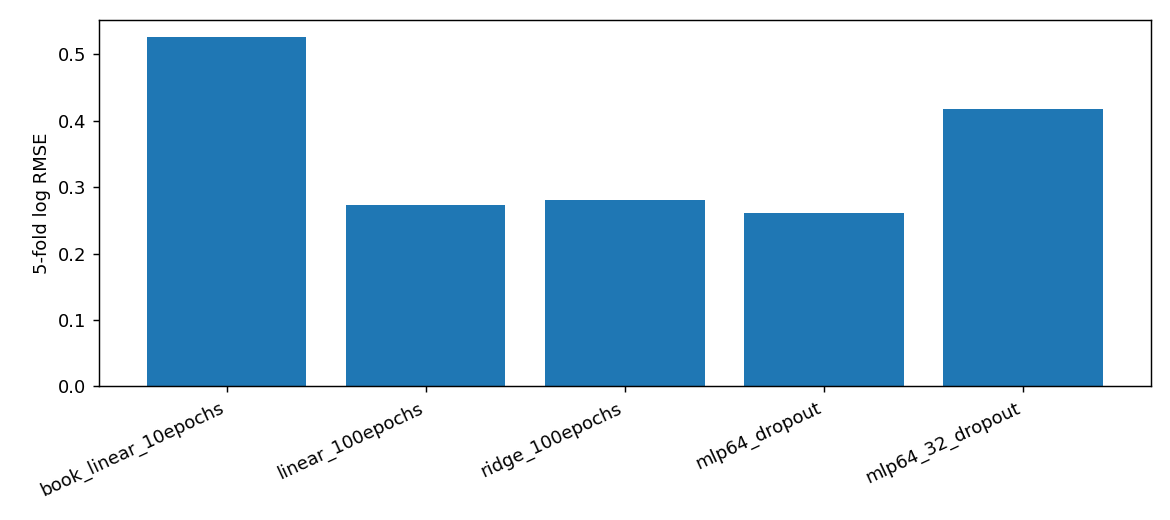

In [8]:
result = run_section("5.7", recompute=RECOMPUTE)
render_result(result)

**Nhận xét từ số đo:** mlp64_dropout có 5-fold log RMSE 0.26146 ± 0.03495; baseline 10 epoch là 0.52599. Đây là CV local, **chưa phải điểm Kaggle**. CSV dự đoán đã tạo, còn thao tác nộp bằng tài khoản cá nhân.

## Phần cần thao tác cá nhân

5.7 câu 1: nộp CSV lên Kaggle và thêm ảnh điểm thật. 5.2 câu 7.1: benchmark GPU chưa đo vì kernel CPU; có `benchmark_gpu.py` để chạy bằng môi trường CUDA. Ảnh/PDF bài làm chưa được upload lên Drive.